# Paso 1. Abrir el archivo de datos y leer la información general

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import chi2_contingency
import numpy as np

In [2]:
logs = pd.read_csv('/datasets/logs_exp_us.csv', sep='\t')

# Paso 2. Preparar los datos para el análisis

### Cambia el nombre de las columnas de manera que sea conveniente para ti.

In [3]:
# Primero revisamos qué contiene nuestro dataset
logs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   EventName       244126 non-null  object
 1   DeviceIDHash    244126 non-null  int64 
 2   EventTimestamp  244126 non-null  int64 
 3   ExpId           244126 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 7.5+ MB


In [4]:
logs.columns = ['event_name', 'device_id_hash', 'event_timestamp', 'exp_id']
logs.head()

,event_name,device_id_hash,event_timestamp,exp_id
0,MainScreenAppear,4575588528974610257,1564029816,246
1,MainScreenAppear,7416695313311560658,1564053102,246
2,PaymentScreenSuccessful,3518123091307005509,1564054127,248
3,CartScreenAppear,3518123091307005509,1564054127,248
4,PaymentScreenSuccessful,6217807653094995999,1564055322,248


### Comprueba los tipos de datos y valores ausentes. Corrige los datos si es necesario.

In [5]:
# Verificamos los tipos de datos
print(logs.dtypes)

event_name         object
device_id_hash      int64
event_timestamp     int64
exp_id              int64
dtype: object


In [6]:
# Verificamos si hay valores ausentes
print(logs.isnull().sum())

event_name         0
device_id_hash     0
event_timestamp    0
exp_id             0
dtype: int64


### Agrega una columna de fecha y hora y una columna separada para las fechas.

In [7]:
# Primero convertimos a formato de fecha y hora
logs['event_timestamp'] = pd.to_datetime(logs['event_timestamp'], unit = 's')

In [8]:
# Ahora, agregamos una columna de fecha
logs['date'] = logs['event_timestamp'].dt.date
logs.head()

,event_name,device_id_hash,event_timestamp,exp_id,date
0,MainScreenAppear,4575588528974610257,2019-07-25 04:43:36,246,2019-07-25
1,MainScreenAppear,7416695313311560658,2019-07-25 11:11:42,246,2019-07-25
2,PaymentScreenSuccessful,3518123091307005509,2019-07-25 11:28:47,248,2019-07-25
3,CartScreenAppear,3518123091307005509,2019-07-25 11:28:47,248,2019-07-25
4,PaymentScreenSuccessful,6217807653094995999,2019-07-25 11:48:42,248,2019-07-25


# Paso 3. Estudiar y comprobar los datos

### ¿Cuántos eventos hay en los registros?

In [9]:
num_events = logs['event_name'].count()
num_events

244126

In [10]:
# Podemos ver también cuántos eventos únicos hay y cuáles son
print('Número de eventos únicos: ', logs['event_name'].nunique())
print(logs['event_name'].unique())

Número de eventos únicos:  5
['MainScreenAppear' 'PaymentScreenSuccessful' 'CartScreenAppear'
 'OffersScreenAppear' 'Tutorial']


### ¿Cuántos usuarios hay en los registros?

In [11]:
num_users = logs['device_id_hash'].nunique()
print(num_users)

7551


### ¿Cuál es el promedio de eventos por usuario?

In [12]:
avg_evus = num_events / num_users
print(avg_evus)

32.33028737915508


### ¿Qué periodo de tiempo cubren los datos?

In [13]:
min_time = logs['date'].min()
max_time = logs['date'].max()

print('Tiempo mínimo:', min_time, 'Tiempo máximo:', max_time)

Tiempo mínimo: 2019-07-25 Tiempo máximo: 2019-08-07


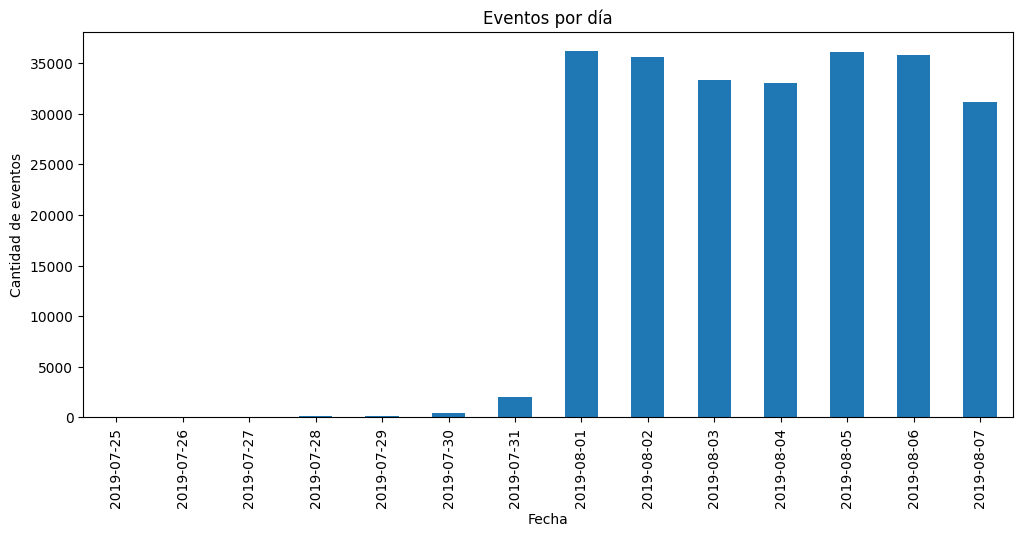

In [14]:
# Hacemos un histograma por fecha y hora
plt.figure(figsize=(12,5))
logs['date'].value_counts().sort_index().plot(kind='bar')
plt.title("Eventos por día")
plt.xlabel("Fecha")
plt.ylabel("Cantidad de eventos")
plt.show()

Lo que podemos evidenciar en el histograma es que, para la primera mitad del período, no hay suficientes datos, por lo cual debemos entrar a ver la cantidad de eventos por día.

In [15]:
# Averiguamos el número de eventos por día para saber exactamente de donde parte la diferencia
ev_per_day = logs.groupby('date')['event_name'].count()
ev_per_day

date
2019-07-25        9
2019-07-26       31
2019-07-27       55
2019-07-28      105
2019-07-29      184
2019-07-30      413
2019-07-31     2031
2019-08-01    36229
2019-08-02    35606
2019-08-03    33351
2019-08-04    33033
2019-08-05    36113
2019-08-06    35822
2019-08-07    31144
Name: event_name, dtype: int64

Viendo estos datos, podemos ver que hay un salto significativo en la cantidad de eventos del 31 de julio (2.031 eventos) al 1 de agosto (36.229 eventos), lo que sugiere que los datos anteriores al 1 de agosto podrían no ser representativos del comportamiento normal de la aplicación.

In [16]:
# Filtramos los datos de nuestro dataset original a partir del 1 de agosto
logs_cl = logs[logs['event_timestamp'] >= '2019-08-01']
# Comprobamos que sí hayan quedado filtrados
ev_per_day_cl = logs_cl.groupby('date')['event_name'].count()
ev_per_day_cl

date
2019-08-01    36229
2019-08-02    35606
2019-08-03    33351
2019-08-04    33033
2019-08-05    36113
2019-08-06    35822
2019-08-07    31144
Name: event_name, dtype: int64

El período representativo en este caso, es la primera semana de agosto de 2019, comprendida entre el 2019-08-01 y el 2019-08-07.

### ¿Se perdieron muchos eventos y usuarios al excluir los datos más antiguos?

In [17]:
# Verificamos el número de eventos perdidos
rest_events = logs_cl['event_name'].count()
lost_events = num_events - rest_events
lost_events

2828

In [18]:
# Ahora sacamos el porcentaje de eventos perdidos
print('Eventos perdidos:', lost_events/num_events * 100)

Eventos perdidos: 1.1584181938834865


Teniendo en cuenta que el total de la muestra era de 244.126, realmente perder el 1,16% (2.828 eventos) de los datos no impacta significativamente nuestro análisis. Tocaría entrar a ver si el período comprendido (que ahora es solo de una semana) sí impacta o no nuestro análisis.

### Asegurarse de tener usuarios de los tres grupos experimentales

In [19]:
# Queremos saber cómo se distribuyen los usuarios entre los tres grupos experimentales
users_per_group = logs_cl.groupby('exp_id')['device_id_hash'].nunique()
print(users_per_group)

exp_id
246    2484
247    2513
248    2537
Name: device_id_hash, dtype: int64


In [20]:
# Verificamos la cantidad total de usarios restantes
clean_users = logs_cl['device_id_hash'].nunique()
clean_users

7534

In [21]:
# Verificamos cuántos usuarios se perdieron en la limpieza de los datos
rest_users =  num_users - clean_users
rest_users

17

# Paso 4. Estudiar el embudo de eventos

### Eventos en los registros y su frecuencia de suceso

In [22]:
# Vamos a contar la veces que aparece cada evento
event_freq = logs_cl['event_name'].value_counts()
print(event_freq)

MainScreenAppear           117431
OffersScreenAppear          46350
CartScreenAppear            42365
PaymentScreenSuccessful     34113
Tutorial                     1039
Name: event_name, dtype: int64


### Cantidad de usuarios que realizaron cada una de estas acciones

In [23]:
users_per_event = logs_cl.groupby('event_name')['device_id_hash'].nunique().sort_values(ascending=False)
users_per_event

event_name
MainScreenAppear           7419
OffersScreenAppear         4593
CartScreenAppear           3734
PaymentScreenSuccessful    3539
Tutorial                    840
Name: device_id_hash, dtype: int64

### Proporción de usuarios que hicieron cada acción

In [24]:
prop_users = (users_per_event / clean_users) * 100
prop_users

event_name
MainScreenAppear           98.473586
OffersScreenAppear         60.963632
CartScreenAppear           49.561986
PaymentScreenSuccessful    46.973719
Tutorial                   11.149456
Name: device_id_hash, dtype: float64

### ¿En qué orden ocurrieron las acciones? ¿Todas son parte de una sola secuencia?

Teniendo en cuenta los resultados, el orden de ocurrencia sería:

1. MainScreenAppear
2. OffersScreenAppear
3. CartScreenAppear
4. PaymentScreenSuccessful

El de Tutorial puede darse en cualquier momento, o no suceder nunca. 

In [25]:
# Definimos el embudo de eventos
funnel_events = ['MainScreenAppear', 'OffersScreenAppear', 'CartScreenAppear', 'PaymentScreenSuccessful']

In [26]:
# Filtramos solo los eventos del embudo
logs_funnel = logs_cl[logs_cl['event_name'].isin(funnel_events)]

In [27]:
# Contamos los usuarios únicos por evento, manteniendo el orden
users_per_st = (logs_funnel.groupby('event_name')['device_id_hash'].nunique().reindex(funnel_events))
users_per_st

event_name
MainScreenAppear           7419
OffersScreenAppear         4593
CartScreenAppear           3734
PaymentScreenSuccessful    3539
Name: device_id_hash, dtype: int64

El evento Tutorial se excluyó porque no forma parte del flujo principal de compra y solo aparece en algunos usuarios.

### Utilizar el embudo de eventos para encontrar la proporción de usuarios que pasan de una etapa a la siguiente.

In [28]:
conversions = (users_per_st / users_per_st.shift(1))*100
conversions

event_name
MainScreenAppear                 NaN
OffersScreenAppear         61.908613
CartScreenAppear           81.297627
PaymentScreenSuccessful    94.777718
Name: device_id_hash, dtype: float64

Tenemos que de Main a Offers, la tasa de conversión es del 61,9%, de Offers a Cart es del 81,3% y de Cart a Payment es del 94,8%. Esto nos indica que las tasas de conversión son realmente altas de una etapa a otra, cuando los usuarios acceden a la ofertas. Este puede ser un valor determinante, pero podríamos entrar a ver (en otro análisis) el impacto en las ganancias.

### ¿En qué etapa se pierden más usuarios?

In [29]:
loss = users_per_st.shift(1) - users_per_st
loss

event_name
MainScreenAppear              NaN
OffersScreenAppear         2826.0
CartScreenAppear            859.0
PaymentScreenSuccessful     195.0
Name: device_id_hash, dtype: float64

Al medir las pérdidas de usuarios en cada etapa, podemos constatar que el momento que genera más pérdidas es el paso de Main a Offers (2.826 usuarios).

### ¿Qué porcentaje de usuarios hace todo el viaje desde su primer evento hasta el pago?

In [30]:
# Sacamos primero los usuarios del inicio y los remanentes
users_b = users_per_st.iloc[0]
users_e = users_per_st.iloc[-1]

# Calculamos el porcentaje
total_pc = (users_e / users_b) * 100
print(f'{total_pc:.2f}%')

47.70%


De acuerdo con nuestro resultado, podemos concluír que el 47,7% de los usuarios llega hasta la etapa final del embudo. Realmente es una tasa de convesión final muy alta, teniendo en cuenta, por supuesto, que se están realizando ofertas para incentivar la conversión.

# Paso 5. Estudiar los resultados del experimento

### ¿Cuántos usuarios hay en cada grupo?

In [31]:
# Filtramos los datos por grupo
group_246 = logs_cl[logs_cl['exp_id'] == 246]
group_247 = logs_cl[logs_cl['exp_id'] == 247]
group_248 = logs_cl[logs_cl['exp_id'] == 248]

In [32]:
users_per_group = logs_cl.groupby('exp_id')['device_id_hash'].nunique()
print(users_per_group)

exp_id
246    2484
247    2513
248    2537
Name: device_id_hash, dtype: int64


### Comprobar si 246 y 247 son estadísticamente iguales (test A/A)

In [33]:
# Buscamos el evento más popular
most_popular = logs_cl['event_name'].value_counts().sort_values(ascending=False).index[0]
most_popular

'MainScreenAppear'

In [34]:
# Ahora, buscamos a los usuarios que participaron de este evento en ambos grupos
u246 = group_246[group_246['event_name'] == most_popular]['device_id_hash'].nunique()
u247 = group_247[group_247['event_name'] == most_popular]['device_id_hash'].nunique()

n246 = group_246['device_id_hash'].nunique()
n247 = group_247['device_id_hash'].nunique()

p246 = u246 / n246
p247 = u247 / n247

print(p246, p247)

0.9863123993558777 0.9852765618782332


In [35]:
# Buscamos los éxitos y fracasos para cada caso
success_246 = u246  # usuarios que participaron en el evento
fails_246 = n246 - u246

success_247 = u247
fails_247 = n247 - u247

# Creamos la tabla de contingencia 2x2
table = [[success_246, fails_246], [success_247, fails_247]]

In [36]:
# Test chi-cuadrado
chi2, p_value = stats.chi2_contingency(table)[:2]
print(f'p-value: {p_value:.4f}')

p-value: 0.8495


Teniendo en cuenta el valor de nuestro p-value, podemos decir que hay un 84,95% de probabilidad de observar estas diferencias por pura casualidad. Esto confirma que los grupos 246 y 247 son estadísticamente iguales, si tomamos como refetencia α = 0,05.

Un p-value alto en A/A testing es exactamente lo que queremos porque confirma que la selección aleatoria de los usuarios fue correcta. Asimismo, confirma que no hay sesgos en la división de grupos y nos da confianza para proceder con las comparaciones A/B.

### Repetir la prueba para todos los eventos

In [37]:

def chi2_event(event, group_a, group_b):
    
    u_a = group_a[group_a['event_name'] == event]['device_id_hash'].nunique()
    u_b = group_b[group_b['event_name'] == event]['device_id_hash'].nunique()
    
    n_a = group_a['device_id_hash'].nunique()
    n_b = group_b['device_id_hash'].nunique()
    
    table = np.array([[u_a, n_a - u_a], [u_b, n_b - u_b]])
    
    chi2, p_value = stats.chi2_contingency(table)[:2] 

    return u_a, u_b, p_value

In [38]:
# Probamos que nuestra función sirva
u_a, u_b, p_value = chi2_event('MainScreenAppear', group_246, group_247)
print(f"Usuarios grupo 246: {u_a}")
print(f"Usuarios grupo 247: {u_b}")
print(f"P-value: {p_value:.4f}")

Usuarios grupo 246: 2450
Usuarios grupo 247: 2476
P-value: 0.8495


In [39]:
# Para el evento OffersScreenAppear
u_a2, u_b2, p_value2 = chi2_event('OffersScreenAppear', group_246, group_247)
print(f"OffersScreenAppear  P-value: {p_value2:.4f}")

OffersScreenAppear  P-value: 0.2602


In [40]:
# Para el evento CartScreenAppear
u_a2, u_b2, p_value2 = chi2_event('CartScreenAppear', group_246, group_247)
print(f"CartScreenAppear  P-value: {p_value2:.4f}")

CartScreenAppear  P-value: 0.2400


In [41]:
# Para el evento PaymentScreenSuccessful
u_a2, u_b2, p_value2 = chi2_event('PaymentScreenSuccessful', group_246, group_247)
print(f"PaymentScreenSuccessful  P-value: {p_value2:.4f}")

PaymentScreenSuccessful  P-value: 0.1212


Podemos concluír, para los demás eventos, que no se observan diferencias significativas para ambos grupos, ya que todos los valores p arrojados fueron mayores a nuestro nivel de significancia, que es 0,05.

### Comparar el grupo experimental (248) con ambos controles

In [42]:
# Comparación 248 vs 246 para todos los eventos del embudo
for event in funnel_events:
    u_248, u_246, p_value = chi2_event(event, group_248, group_246)
    
    # Calculamos las proporciones
    prop_248 = u_248 / group_248['device_id_hash'].nunique()
    prop_246 = u_246 / group_246['device_id_hash'].nunique()
    
    print(f"Evento: {event}")
    print(f"  Grupo 248: {u_248} usuarios ({prop_248:.4f})")
    print(f"  Grupo 246: {u_246} usuarios ({prop_246:.4f})")
    print(f"  P-value: {p_value:.4f}")
    
    if p_value < 0.05:
        print(f"Hay una diferencia significativa (p < 0.05)")
    else:
        print(f"No hay diferencia significativa (p ≥ 0.05)")
    print()

Evento: MainScreenAppear
  Grupo 248: 2493 usuarios (0.9827)
  Grupo 246: 2450 usuarios (0.9863)
  P-value: 0.3507
No hay diferencia significativa (p ≥ 0.05)

Evento: OffersScreenAppear
  Grupo 248: 1531 usuarios (0.6035)
  Grupo 246: 1542 usuarios (0.6208)
  P-value: 0.2190
No hay diferencia significativa (p ≥ 0.05)

Evento: CartScreenAppear
  Grupo 248: 1230 usuarios (0.4848)
  Grupo 246: 1266 usuarios (0.5097)
  P-value: 0.0833
No hay diferencia significativa (p ≥ 0.05)

Evento: PaymentScreenSuccessful
  Grupo 248: 1181 usuarios (0.4655)
  Grupo 246: 1200 usuarios (0.4831)
  P-value: 0.2228
No hay diferencia significativa (p ≥ 0.05)



Comparando nuestro grupo de prueba (248) con el de control (246), para cada evento, podemos concluír que no exite diferencia significativa. Esto nos da a entender que realizar los cambios en el diseño de las fuentes de toda la aplicación, no va a generar ningún cambio significativo, por lo cual no afectaría el comportamiento de los usuarios.

In [43]:
# Comparación 248 vs 247 para todos los eventos del embudo
for event in funnel_events:
    u_248, u_247, p_value = chi2_event(event, group_248, group_247)
    
    # Calculamos las proporciones
    prop_248 = u_248 / group_248['device_id_hash'].nunique()
    prop_247 = u_247 / group_247['device_id_hash'].nunique()
    
    print(f"Evento: {event}")
    print(f"  Grupo 248: {u_248} usuarios ({prop_248:.4f})")
    print(f"  Grupo 247: {u_247} usuarios ({prop_247:.4f})")
    print(f"  P-value: {p_value:.4f}")
    
    if p_value < 0.05:
        print(f"Hay una diferencia significativa (p < 0.05)")
    else:
        print(f"No hay diferencia significativa (p ≥ 0.05)")
    print()

Evento: MainScreenAppear
  Grupo 248: 2493 usuarios (0.9827)
  Grupo 247: 2476 usuarios (0.9853)
  P-value: 0.5294
No hay diferencia significativa (p ≥ 0.05)

Evento: OffersScreenAppear
  Grupo 248: 1531 usuarios (0.6035)
  Grupo 247: 1520 usuarios (0.6049)
  P-value: 0.9427
No hay diferencia significativa (p ≥ 0.05)

Evento: CartScreenAppear
  Grupo 248: 1230 usuarios (0.4848)
  Grupo 247: 1238 usuarios (0.4926)
  P-value: 0.5980
No hay diferencia significativa (p ≥ 0.05)

Evento: PaymentScreenSuccessful
  Grupo 248: 1181 usuarios (0.4655)
  Grupo 247: 1158 usuarios (0.4608)
  P-value: 0.7587
No hay diferencia significativa (p ≥ 0.05)



Al igual que la prueba anterior, comparando nuestro grupo de 248 con 247, para cada evento, podemos concluír que no exite diferencia significativa. Por lo cual, realizar los cambios en el diseño de las fuentes de toda la aplicación, no va a generar ningún cambio significativo, y no afectaría el comportamiento de los usuarios.

### Comparar grupo experimental contra ambos grupos combinados

In [44]:
# Combinamos los grupos de control 246 y 247
control_combined = pd.concat([group_246, group_247])

In [45]:
# Realizamos la prueba para cada evento del embudo
for event in funnel_events:
    u_248, u_control, p_value = chi2_event(event, group_248, control_combined)
    
    # Calculamos las proporciones
    prop_248 = u_248 / group_248['device_id_hash'].nunique()
    prop_control = u_control / control_combined['device_id_hash'].nunique()
    
    print(f"Evento: {event}")
    print(f"  Grupo 248: {u_248} usuarios ({prop_248:.4f})")
    print(f"  Control combinado: {u_control} usuarios ({prop_control:.4f})")
    print(f"  P-value: {p_value:.4f}")
    
    if p_value < 0.05:
        print(f"Diferencia SIGNIFICATIVA (p < 0.05)")
    else:
        print(f"No hay diferencia significativa (p ≥ 0.05)")
    print()

# Verificamos el tamaño de la muestra combinada
print(f"Tamaño grupo experimental: {group_248['device_id_hash'].nunique()}")
print(f"Tamaño control combinado: {control_combined['device_id_hash'].nunique()}")

Evento: MainScreenAppear
  Grupo 248: 2493 usuarios (0.9827)
  Control combinado: 4926 usuarios (0.9858)
  P-value: 0.3424
No hay diferencia significativa (p ≥ 0.05)

Evento: OffersScreenAppear
  Grupo 248: 1531 usuarios (0.6035)
  Control combinado: 3062 usuarios (0.6128)
  P-value: 0.4491
No hay diferencia significativa (p ≥ 0.05)

Evento: CartScreenAppear
  Grupo 248: 1230 usuarios (0.4848)
  Control combinado: 2504 usuarios (0.5011)
  P-value: 0.1899
No hay diferencia significativa (p ≥ 0.05)

Evento: PaymentScreenSuccessful
  Grupo 248: 1181 usuarios (0.4655)
  Control combinado: 2358 usuarios (0.4719)
  P-value: 0.6175
No hay diferencia significativa (p ≥ 0.05)

Tamaño grupo experimental: 2537
Tamaño control combinado: 4997


Resultados del experimento A/A/B:

Los grupos 246, 247 y 248 contienen tamaños similares, lo cual es adecuado para un experimento A/A/B.

Prueba A/A (246 vs 247): Se realizaron pruebas de diferencia de proporciones para todos los eventos y se pudo concluír que en la mayoría de los casos no se observaron diferencias estadísticamente significativas bajo un nivel de significancia de 0.05. Esto confirma que la división en grupos fue correcta y aleatoria.

Comparación del grupo experimental 248 con los grupos de control:
Al comparar cada evento, no se detectaron diferencias significativas consistentes entre el grupo 248 y los grupos de control. Comparando 248 contra ambos grupos de control combinados, los resultados se mantuvieron similares.
Esto indica que la nueva fuente no afectó el comportamiento de los usuarios.

Al escoger el nivel de significancia, nos dimos cuenta de lo siguiente:
Si utilizamos α = 0,10 implicaría encontrar falsos positivos frecuentes (1 por cada 10 pruebas). Por lo tanto nos decidimos por un α = 0,05.
No se aplica correcciones de Bonferroni porque no tendría ningún sentido, teniendo en cuenta que nuestro p-value más bajo es de 0.0833 en todas nuestras pruebas estadísticas.

Podemos concluir, entonces, no existe evidencia estadística de que el cambio de fuentes modifique la interacción con la aplicación. Por lo tanto, el nuevo diseño puede implementarse sin riesgos.